# Exploratory Data Analysis: Superstore Retail Sales

**Goal:** analyze customer purchase volume, monthly seasonality, category-wise revenue and discount sensitivity, and draw executive takeaways.

**Dataset:** `superstore_sales.csv` (order lines, 2015-2018).

**Notebook structure**
1. Load the data and profile its quality
2. Clean the data (junk rows, missing values, dates, duplicates, Year-Month)
3. Aggregate by Category, Region and Segment
4. Customer purchase volume
5. Monthly sales velocity and seasonality
6. Discount sensitivity
7. Five annotated business findings

> Place `superstore_sales.csv` in the same folder as this notebook before running it.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

## 2. Load the data and profile its quality

In [2]:
# The file uses a legacy single-byte encoding (latin-1); Postal Code is read as text so leading zeros are not lost
raw = pd.read_csv("superstore_sales.csv", encoding="latin-1", dtype={"Postal Code": str})
print("Raw shape:", raw.shape)
raw.head()

Raw shape: (10800, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2.00,0.00,41.91
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3.00,0.00,219.58
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2.00,0.00,6.87
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5.00,0.45,-383.03
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2.00,0.20,2.52


In [3]:
# Missing-value profile BEFORE cleaning
before = raw.isna().sum()
before[before > 0]

Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64

**Observation:** the raw file has far more missing values than a normal Superstore extract. Every column except two is missing hundreds of values. That pattern points to blank or foreign rows, not random gaps, so let's look at the end of the file.

In [4]:
raw.tail(8)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
10792,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10793,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10794,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10795,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10796,Yes,US-2018-147998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10797,Yes,US-2018-151127,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10798,Yes,US-2018-155999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10799,Yes,US-2018-155999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


The last rows belong to **two other tables** (a "People" lookup and a "Returns" list) that were appended below the order data. They have no `Category`, so that column identifies them reliably.

## 3. Clean the data

### 3.1 Remove the appended junk rows

In [5]:
df = raw.dropna(subset=["Category"]).copy()
print(f"Rows removed: {len(raw) - len(df)}")
print(f"Rows kept   : {len(df)}")

Rows removed: 806
Rows kept   : 9994


### 3.2 Handle missing values

In [6]:
# Only Postal Code remains incomplete after removing the junk rows
missing = df.isna().sum()
print(missing[missing > 0])
print()
print(df.loc[df["Postal Code"].isna(), ["City", "State"]].drop_duplicates())

Postal Code    11
dtype: int64

            City    State
2234  Burlington  Vermont


All missing postal codes belong to **Burlington, Vermont**, so they can be filled safely with that city's ZIP code, `05401`, rather than dropped.

In [7]:
df["Postal Code"] = df["Postal Code"].fillna("05401").astype(str).str.zfill(5)
print("Missing values left:", int(df.isna().sum().sum()))

Missing values left: 0


### 3.3 Parse dates and extract Year-Month

In [8]:
# Explicit US format (month/day/year) so dates are never misread by regional settings
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")

df["Year"] = df["Order Date"].dt.year
df["Month Num"] = df["Order Date"].dt.month
df["Year-Month"] = df["Order Date"].dt.to_period("M").astype(str)

print(df["Order Date"].min().date(), "to", df["Order Date"].max().date())
df[["Order Date", "Year", "Month Num", "Year-Month"]].head()

2015-01-03 to 2018-12-30


,Order Date,Year,Month Num,Year-Month
0,2017-11-08,2017,11,2017-11
1,2017-11-08,2017,11,2017-11
2,2017-06-12,2017,6,2017-06
3,2016-10-11,2016,10,2016-10
4,2016-10-11,2016,10,2016-10


### 3.4 Fix numeric types and remove duplicates

In [9]:
for col in ["Row ID", "Quantity"]:
    df[col] = df[col].astype(int)
for col in ["Sales", "Discount", "Profit"]:
    df[col] = df[col].astype(float)

# A true duplicate repeats every field except the surrogate Row ID
dupes = df.duplicated(subset=df.columns.drop("Row ID"), keep="first")
print("Duplicate order lines:", int(dupes.sum()))
df = df[~dupes].reset_index(drop=True)

print("Final clean shape:", df.shape)

Duplicate order lines: 1
Final clean shape: (9993, 24)


In [10]:
# Missing-value profile AFTER cleaning
print("Missing values:", int(df.isna().sum().sum()))
print(f"Total Sales : ${df['Sales'].sum():,.2f}")
print(f"Total Profit: ${df['Profit'].sum():,.2f}")
print(f"Overall margin: {df['Profit'].sum() / df['Sales'].sum():.1%}")

Missing values: 0
Total Sales : $2,296,919.49
Total Profit: $286,409.08
Overall margin: 12.5%


**Cleaning summary**

| Issue | Action | Result |
|---|---|---|
| 806 rows from other tables | Dropped rows with no Category | 9,994 order lines |
| 11 missing Postal Codes (Burlington, VT) | Filled with `05401` | 0 missing |
| Dates stored as text | Parsed as month/day/year | 2015-01-03 to 2018-12-30 |
| 1 duplicate order line | Removed | 9,993 rows |
| No time grouping field | Added Year, Month Num, Year-Month | Ready for trend analysis |

## 4. Aggregate by Category, Region and Segment

In [11]:
def summarize(by):
    t = df.groupby(by).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Orders=("Order ID", "nunique"))
    t["Margin %"] = t["Profit"] / t["Sales"] * 100
    return t.sort_values("Sales", ascending=False)

cat = summarize("Category")
reg = summarize("Region")
seg = summarize("Segment")
cat

,Sales,Profit,Orders,Margin %
Category,,,,
Technology,"836,154.03","145,454.95",1544,17.40
Furniture,"741,718.42","18,463.33",1764,2.49
Office Supplies,"719,047.03","122,490.80",3742,17.04


In [12]:
reg

,Sales,Profit,Orders,Margin %
Region,,,,
West,"725,457.82","108,418.45",1611,14.94
East,"678,499.87","91,534.84",1401,13.49
Central,"501,239.89","39,706.36",1175,7.92
South,"391,721.91","46,749.43",822,11.93


In [13]:
seg

,Sales,Profit,Orders,Margin %
Segment,,,,
Consumer,"1,161,401.34","134,119.21",2586,11.55
Corporate,"706,146.37","91,979.13",1514,13.03
Home Office,"429,371.78","60,310.74",909,14.05


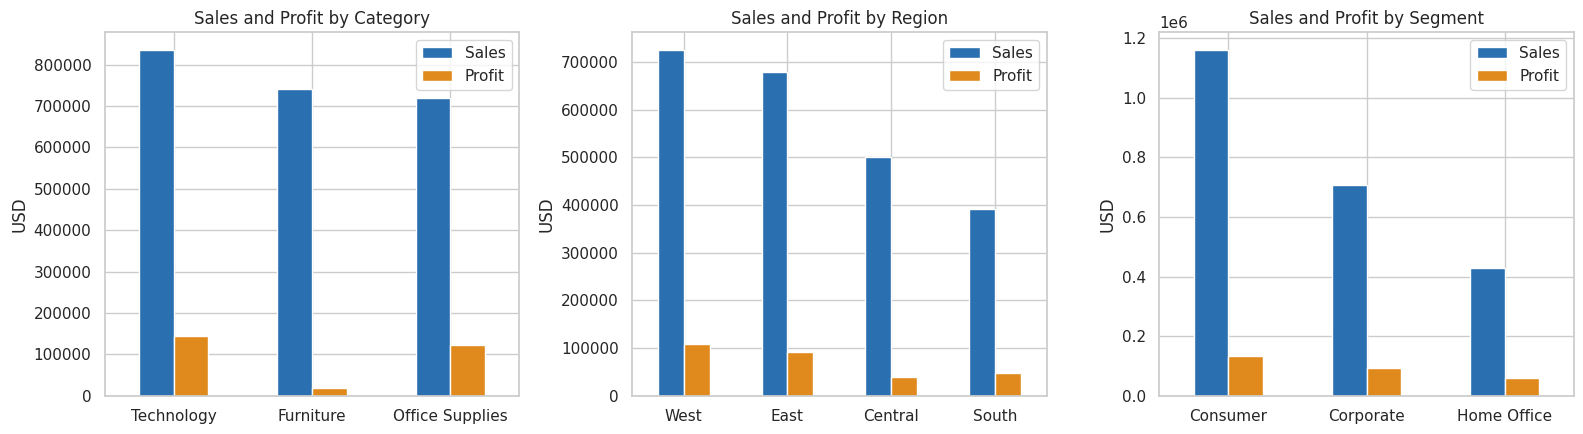

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, t) in zip(axes, [("Category", cat), ("Region", reg), ("Segment", seg)]):
    t[["Sales", "Profit"]].plot(kind="bar", ax=ax, color=["#2a6fb0", "#e08a1e"])
    ax.set_title(f"Sales and Profit by {name}")
    ax.set_xlabel("")
    ax.set_ylabel("USD")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

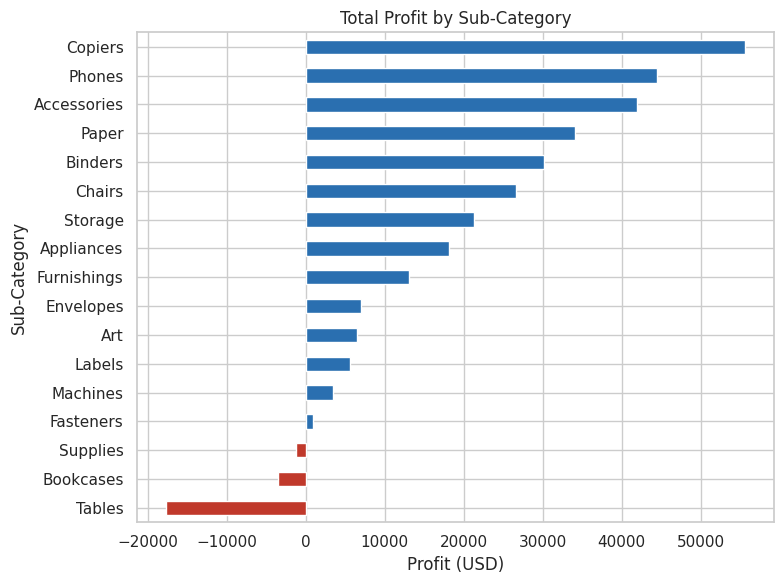

Sub-Category
Tables      -17,725.48
Bookcases    -3,472.56
Supplies     -1,189.10
Fasteners       949.52
Name: Profit, dtype: float64

In [15]:
sub = df.groupby("Sub-Category")["Profit"].sum().sort_values()
plt.figure(figsize=(8, 6))
colors = ["#c0392b" if v < 0 else "#2a6fb0" for v in sub]
sub.plot(kind="barh", color=colors)
plt.title("Total Profit by Sub-Category")
plt.xlabel("Profit (USD)")
plt.tight_layout()
plt.show()
sub.head(4)

## 5. Customer purchase volume

In [16]:
cust = df.groupby("Customer Name").agg(Sales=("Sales", "sum"), Orders=("Order ID", "nunique")).sort_values("Sales", ascending=False)
print("Customers:", len(cust))
cust.head(10)

Customers: 793


,Sales,Orders
Customer Name,,
Sean Miller,"25,043.05",5
Tamara Chand,"19,052.22",5
Raymond Buch,"15,117.34",6
Tom Ashbrook,"14,595.62",4
Adrian Barton,"14,473.57",10
Ken Lonsdale,"14,175.23",12
Sanjit Chand,"14,142.33",9
Hunter Lopez,"12,873.30",6
Sanjit Engle,"12,209.44",11


Top 20% of customers (158) generate 48.0% of sales


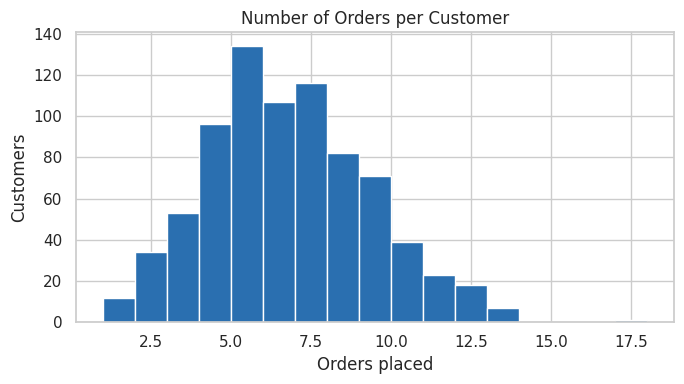

In [17]:
cust["Cumulative Share"] = cust["Sales"].cumsum() / cust["Sales"].sum()
top20_n = int(len(cust) * 0.2)
share = cust["Sales"].head(top20_n).sum() / cust["Sales"].sum()
print(f"Top 20% of customers ({top20_n}) generate {share:.1%} of sales")

plt.figure(figsize=(7, 4))
plt.hist(cust["Orders"], bins=range(1, int(cust["Orders"].max()) + 2), color="#2a6fb0", edgecolor="white")
plt.title("Number of Orders per Customer")
plt.xlabel("Orders placed")
plt.ylabel("Customers")
plt.tight_layout()
plt.show()

## 6. Monthly sales velocity and seasonality

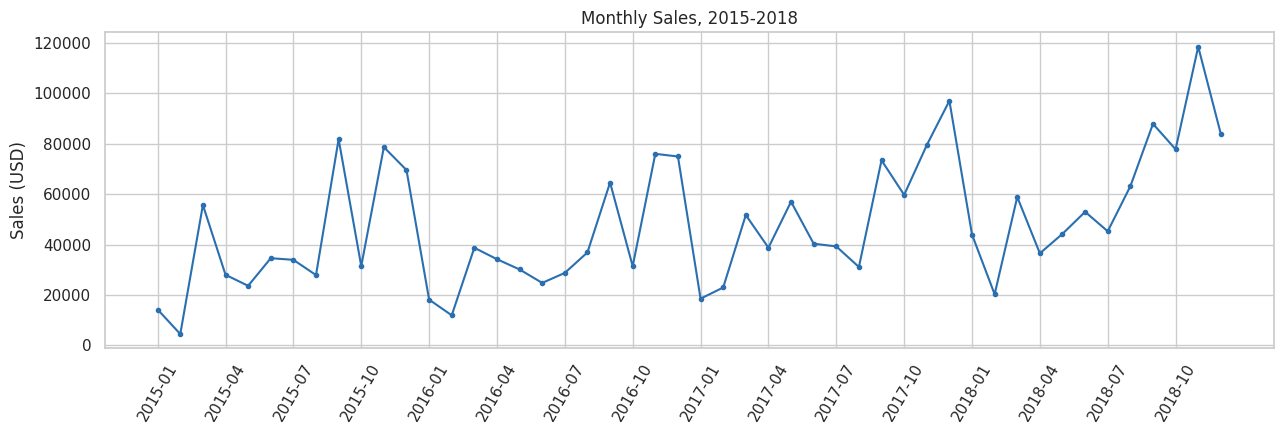

In [18]:
monthly = df.groupby("Year-Month")["Sales"].sum()
plt.figure(figsize=(13, 4.5))
plt.plot(monthly.index, monthly.values, marker="o", markersize=3, color="#2a6fb0")
plt.xticks(range(0, len(monthly), 3), monthly.index[::3], rotation=60)
plt.title("Monthly Sales, 2015-2018")
plt.ylabel("Sales (USD)")
plt.tight_layout()
plt.show()

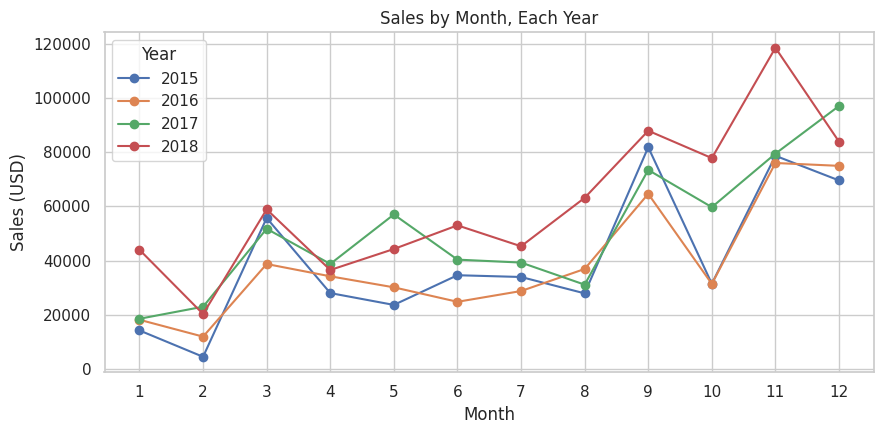

Sep-Dec share of total sales: 51.6%
Jan-Feb share of total sales: 6.7%


In [19]:
pivot = df.pivot_table(index="Month Num", columns="Year", values="Sales", aggfunc="sum")
pivot.plot(figsize=(9, 4.5), marker="o")
plt.title("Sales by Month, Each Year")
plt.xlabel("Month")
plt.ylabel("Sales (USD)")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

month_totals = pivot.sum(axis=1)
print(f"Sep-Dec share of total sales: {month_totals.loc[9:12].sum() / month_totals.sum():.1%}")
print(f"Jan-Feb share of total sales: {month_totals.loc[1:2].sum() / month_totals.sum():.1%}")

In [20]:
yearly = df.groupby("Year").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
yearly["Margin %"] = yearly["Profit"] / yearly["Sales"] * 100
yearly["Sales Growth %"] = yearly["Sales"].pct_change() * 100
yearly

,Sales,Profit,Margin %,Sales Growth %
Year,,,,
2015,"483,966.13","49,556.03",10.24,NaN
2016,"470,532.51","61,618.60",13.10,-2.78
2017,"609,205.60","81,795.17",13.43,29.47
2018,"733,215.26","93,439.27",12.74,20.36


## 7. Discount sensitivity

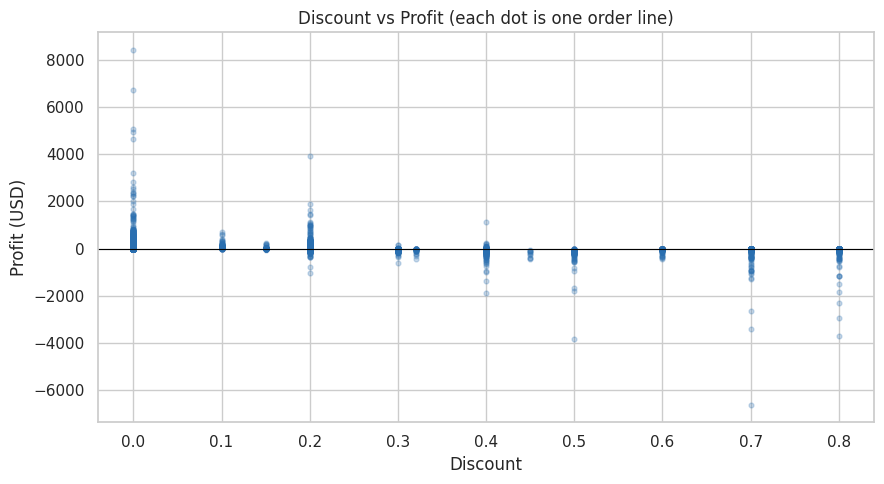

In [21]:
plt.figure(figsize=(9, 5))
plt.scatter(df["Discount"], df["Profit"], alpha=0.25, s=12, color="#2a6fb0")
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Discount vs Profit (each dot is one order line)")
plt.xlabel("Discount")
plt.ylabel("Profit (USD)")
plt.tight_layout()
plt.show()

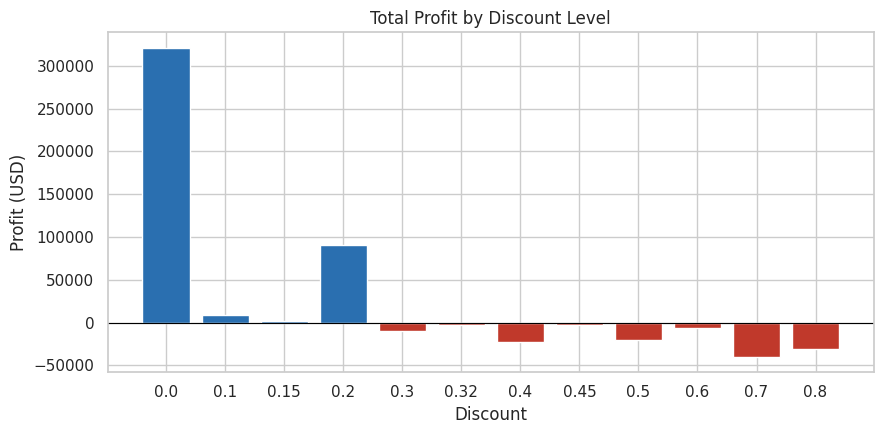

,Sales,Profit,Lines,Margin %
Discount,,,,
0.00,"1,087,908.47","320,987.60",4798,29.51
0.10,"54,369.35","9,029.18",94,16.61
0.15,"27,558.52","1,418.99",52,5.15
0.20,"764,594.37","90,337.31",3657,11.82
0.30,"102,945.28","-10,357.22",226,-10.06
0.32,"14,493.46","-2,391.14",27,-16.50
0.40,"116,417.78","-23,057.05",206,-19.81
0.45,"5,484.97","-2,493.11",11,-45.45
0.50,"58,918.54","-20,506.43",66,-34.80


In [22]:
disc = df.groupby("Discount").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Lines=("Row ID", "count"))
disc["Margin %"] = disc["Profit"] / disc["Sales"] * 100

plt.figure(figsize=(9, 4.5))
colors = ["#c0392b" if v < 0 else "#2a6fb0" for v in disc["Profit"]]
plt.bar(disc.index.astype(str), disc["Profit"], color=colors)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Total Profit by Discount Level")
plt.xlabel("Discount")
plt.ylabel("Profit (USD)")
plt.tight_layout()
plt.show()
disc

In [23]:
deep = df[df["Discount"] >= 0.30]
print(f"Orders with discount >= 30%: {len(deep):,} lines")
print(f"  Sales : ${deep['Sales'].sum():,.0f} ({deep['Sales'].sum() / df['Sales'].sum():.1%} of total)")
print(f"  Profit: ${deep['Profit'].sum():,.0f}")
print(f"Profit without them: ${df['Profit'].sum() - deep['Profit'].sum():,.0f}")

Orders with discount >= 30%: 1,392 lines
  Sales : $362,489 (15.8% of total)
  Profit: $-135,364
Profit without them: $421,773


## 8. Executive Takeaways

### Finding 1: Furniture sells well but barely makes money
Furniture brings in about $742K in sales, the second highest category, but only about $18K in profit, a **2.5% margin**. Office Supplies and Technology earn about 17%. Furniture is roughly 32% of revenue but only about 6% of profit. The sub-category chart shows why: **Tables** and **Bookcases** lose money. *Action: review pricing and supplier costs in Furniture, starting with Tables.*

### Finding 2: Discounts of 30% or more destroy profit
Profit is strong at 0% discount (about $321K) and still positive at 20% (about $90K). **Every discount level from 30% upward is loss-making.** Orders discounted 30% or more make up about 16% of sales but lose roughly **$135K**, so profit would be around $422K instead of $286K without them. *Action: cap discounts at 20% unless a manager approves an exception.*

### Finding 3: Sales are strongly seasonal
September to December generate about **52%** of all sales, with November and December the peak months. January and February are the weakest, under 7% of sales together. The pattern repeats in each of the four years, so it is seasonal and not a one-off. *Action: build stock and staffing ahead of September, and run promotions to lift January and February.*

### Finding 4: The Central region has the weakest margin
Central earns a **7.9% margin**, against about 14.9% in West and 13.5% in East. South sells less than Central ($392K vs $501K) yet earns more profit. *Action: investigate discounting and product mix in Central.*

### Finding 5: Sales are growing, but margin slipped in 2018
Sales rose from about $484K in 2015 to $733K in 2018 (about 52% growth). Margin peaked near 13.4% in 2017 and eased to about 12.7% in 2018, so profit is not growing quite as fast as revenue. *Action: track margin alongside revenue so growth does not depend on heavier discounting.*

### Additional observation: customer concentration
The customer analysis in section 5 shows that the top 20% of customers account for about half of sales. *Action: protect and grow these accounts with loyalty offers.*